# Lab 6

You are tasked with evaluating card counting strategies for black jack. In order to do so, you will use object oriented programming to create a playable casino style black jack game where a computer dealer plays against $n$ computer players and possibly one human player. If you don't know the rules of blackjack or card counting, please google it. 

A few requirements:
* The game should utilize multiple 52-card decks. Typically the game is played with 6 decks.
* Players should have chips.
* Dealer's actions are predefined by rules of the game (typically hit on 16). 
* The players should be aware of all shown cards so that they can count cards.
* Each player could have a different strategy.
* The system should allow you to play large numbers of games, study the outcomes, and compare average winnings per hand rate for different strategies.

1. Begin by creating a classes to represent cards and decks. The deck should support more than one 52-card set. The deck should allow you to shuffle and draw cards. Include a "plastic" card, placed randomly in the deck. Later, when the plastic card is dealt, shuffle the cards before the next deal.

2. Now design your game on a UML diagram. You may want to create classes to represent, players, a hand, and/or the game. As you work through the lab, update your UML diagram. At the end of the lab, submit your diagram (as pdf file) along with your notebook. 

3. Begin with implementing the skeleton (ie define data members and methods/functions, but do not code the logic) of the classes in your UML diagram.

4. Complete the implementation by coding the logic of all functions. For now, just implement the dealer player and human player.

5.  Test. Demonstrate game play. For example, create a game of several dealer players and show that the game is functional through several rounds.

6. Implement a new player with the following strategy:

    * Assign each card a value: 
        * Cards 2 to 6 are +1 
        * Cards 7 to 9 are 0 
        * Cards 10 through Ace are -1
    * Compute the sum of the values for all cards seen so far.
    * Hit if sum is very negative, stay if sum is very positive. Select a threshold for hit/stay, e.g. 0 or -2.  

7. Create a test scenario where one player, using the above strategy, is playing with a dealer and 3 other players that follow the dealer's strategy. Each player starts with same number of chips. Play 50 rounds (or until the strategy player is out of money). Compute the strategy player's winnings. You may remove unnecessary printouts from your code (perhaps implement a verbose/quiet mode) to reduce the output.

8. Create a loop that runs 100 games of 50 rounds, as setup in previous question, and store the strategy player's chips at the end of the game (aka "winnings") in a list. Histogram the winnings. What is the average winnings per round? What is the standard deviation. What is the probability of net winning or losing after 50 rounds?


9. Repeat previous questions scanning the value of the threshold. Try at least 5 different threshold values. Can you find an optimal value?

10. Create a new strategy based on web searches or your own ideas. Demonstrate that the new strategy will result in increased or decreased winnings. 

In [2]:
import random

SUITS = ["Hearts", "Diamonds", "Clubs", "Spades"]
RANKS = ["2", "3", "4", "5", "6", "7", "8", "9", "10", "J", "Q", "K", "A"]


class Card:
    def __init__(self, rank, suit):
        self.rank = rank
        self.suit = suit

    def get_value(self):
        # Aces count as 11 here. The hand class can lower it to 1 later.
        if self.rank == "A":
            return 11
        if self.rank in ["J", "Q", "K"]:
            return 10
        if self.rank == "PLASTIC":
            return 0
        return int(self.rank)

    def is_plastic(self):
        return self.rank == "PLASTIC"

    def __str__(self):
        if self.is_plastic():
            return "Plastic card"
        return self.rank + " of " + self.suit


class Deck:
    def __init__(self, num_decks=6):
        self.num_decks = num_decks
        self.cards = []
        self.needs_shuffle = False
        self.shuffle()

    def shuffle(self):
        # Put every card back, shuffle, then hide the plastic card somewhere inside.
        self.cards = []
        for i in range(self.num_decks):
            for suit in SUITS:
                for rank in RANKS:
                    self.cards.append(Card(rank, suit))

        random.shuffle(self.cards)

        # Random spot, but never the very first or last position
        spot = random.randint(1, len(self.cards) - 1)
        self.cards.insert(spot, Card("PLASTIC", ""))

        self.needs_shuffle = False

    def draw(self):
        card = self.cards.pop()

        # If we hit the plastic card, remember to shuffle before the next deal
        # and keep going with the next real card.
        if card.is_plastic():
            self.needs_shuffle = True
            card = self.cards.pop()

        return card

    def cards_left(self):
        return len(self.cards)


In [3]:
# Quick test
if __name__ == "__main__":
    deck = Deck(6)
    print("Cards in deck (including plastic):", deck.cards_left())

    for i in range(5):
        print(deck.draw())

    # Draw until the plastic card shows up
    count = 5
    while not deck.needs_shuffle:
        deck.draw()
        count += 1
    print("Plastic card hit after", count, "cards")

    deck.shuffle()
    print("After shuffle:", deck.cards_left(), "cards, needs_shuffle =", deck.needs_shuffle)

Cards in deck (including plastic): 313
7 of Diamonds
9 of Spades
2 of Clubs
10 of Clubs
8 of Spades
Plastic card hit after 311 cards
After shuffle: 313 cards, needs_shuffle = False


In [16]:
class Hand:
    def __init__(self):
        self.cards = []
        self.bet = 0

    def add_card(self, card):
        self.cards.append(card)

    def get_total(self):
        total = 0
        aces = 0
        for card in self.cards:
            total = total + card.get_value()
            if card.rank == "A":
                aces = aces + 1
        # an ace counts as 11 unless that would bust us, then it counts as 1
        while total > 21 and aces > 0:
            total = total - 10
            aces = aces - 1
        return total

    def is_soft(self):
        total = 0
        aces = 0
        for card in self.cards:
            total = total + card.get_value()
            if card.rank == "A":
                aces = aces + 1
        while total > 21 and aces > 0:
            total = total - 10
            aces = aces - 1
        return aces > 0    # an ace is still counting as 11

    def is_blackjack(self):
        return len(self.cards) == 2 and self.get_total() == 21

    def is_bust(self):
        return self.get_total() > 21

    def clear(self):
        self.cards = []
        self.bet = 0
        
class Strategy:
    def __init__(self, min_bet=10, max_bet=100):
        self.min_bet = min_bet
        self.max_bet = max_bet

    def choose_bet(self, chips):
        return min(self.min_bet, chips)

    def choose_action(self, hand, dealer_card):
        return "stand"

    def see_card(self, card):
        pass

    def reset_count(self):
        pass


class HumanStrategy(Strategy):
    def choose_bet(self, chips):
        lowest = min(self.min_bet, chips)
        highest = min(self.max_bet, chips)
        while True:
            text = input("You have " + str(chips) + " chips. Bet (" + str(lowest) + " to " + str(highest) + "): ")
            if text.isdigit():
                bet = int(text)
                if bet >= lowest and bet <= highest:
                    return bet
            print("That is not a valid bet, try again.")

    def choose_action(self, hand, dealer_card):
        cards_text = ", ".join(str(card) for card in hand.cards)
        print("Your hand: " + cards_text + " (total " + str(hand.get_total()) + ")")
        print("Dealer shows: " + str(dealer_card))
        while True:
            answer = input("Hit or stand? (h/s): ").lower()
            if answer == "h":
                return "hit"
            if answer == "s":
                return "stand"
            print("Please type h or s.")

class Player:
    def __init__(self, name, chips, strategy):
        self.name = name
        self.chips = chips
        self.starting_chips = chips
        self.hand = Hand()
        self.strategy = strategy
        self.hands_played = 0

    def place_bet(self):
        self.hand.bet = self.strategy.choose_bet(self.chips)

    def decide(self, dealer_card):
        return self.strategy.choose_action(self.hand, dealer_card)

    def see_card(self, card):
        self.strategy.see_card(card)

    def win_bet(self):
        if self.hand.is_blackjack():
            self.chips = self.chips + int(self.hand.bet * 1.5)   # blackjack pays 3 to 2
        else:
            self.chips = self.chips + self.hand.bet
        self.hands_played = self.hands_played + 1

    def lose_bet(self):
        self.chips = self.chips - self.hand.bet
        self.hands_played = self.hands_played + 1

    def push_bet(self):
        self.hands_played = self.hands_played + 1

class Dealer:
    def __init__(self, name="Dealer"):
        self.name = name
        self.hand = Hand()

    def up_card(self):
        return self.hand.cards[0]

    def should_hit(self):
        return self.hand.get_total() < 17    # hits on 16, stands on 17

    def play_turn(self, game):
        while self.should_hit():
            game.deal_card(self.hand)

class Game:
    def __init__(self, players, num_decks=6, verbose=True):
        self.deck = Deck(num_decks)
        self.dealer = Dealer()
        self.players = players
        self.hands_played = 0
        self.verbose = verbose

    def say(self, text):
        # only print when verbose is on (we'll turn it off for big simulations)
        if self.verbose:
            print(text)

    def deal_card(self, hand, show=True):
        card = self.deck.draw()
        hand.add_card(card)
        if show:
            for player in self.players:
                player.see_card(card)    # this is how counters see every card
        return card

    def deal_starting_hands(self):
        for i in range(2):
            for player in self.players:
                self.deal_card(player.hand)
            # the dealer's 2nd card is face down, so nobody counts it yet
            self.deal_card(self.dealer.hand, show=(i == 0))
        self.say("Dealer shows: " + str(self.dealer.up_card()))

    def play_players(self):
        for player in self.players:
            while player.hand.get_total() < 21:
                action = player.decide(self.dealer.up_card())
                if action != "hit":
                    break
                card = self.deal_card(player.hand)
                self.say(player.name + " draws " + str(card))
            if player.hand.is_bust():
                self.say(player.name + " busts with " + str(player.hand.get_total()))

    def play_dealer(self):
        # flip the face-down card so everyone can count it
        hole_card = self.dealer.hand.cards[1]
        for player in self.players:
            player.see_card(hole_card)
        self.say("Dealer reveals " + str(hole_card))
        self.dealer.play_turn(self)
        self.say("Dealer total: " + str(self.dealer.hand.get_total()))

    def settle_bets(self):
        dealer_hand = self.dealer.hand
        for player in self.players:
            hand = player.hand
            if hand.is_bust():
                result = "lose"
            elif hand.is_blackjack() and not dealer_hand.is_blackjack():
                result = "win"
            elif dealer_hand.is_blackjack() and not hand.is_blackjack():
                result = "lose"
            elif dealer_hand.is_bust():
                result = "win"
            elif hand.get_total() > dealer_hand.get_total():
                result = "win"
            elif hand.get_total() < dealer_hand.get_total():
                result = "lose"
            else:
                result = "push"

            if result == "win":
                player.win_bet()
            elif result == "lose":
                player.lose_bet()
            else:
                player.push_bet()
            self.say(player.name + ": " + result + ". Chips: " + str(player.chips))

    def check_shuffle(self):
        if self.deck.needs_shuffle:
            self.deck.shuffle()
            for player in self.players:
                player.strategy.reset_count()    # the count starts over after a shuffle
            self.say("Plastic card came out, shuffling the deck.")

    def play_round(self):
        # players with no chips left sit out
        self.players = [p for p in self.players if p.chips > 0]
        if len(self.players) == 0:
            return

        self.dealer.hand.clear()
        for player in self.players:
            player.hand.clear()
            player.place_bet()

        self.deal_starting_hands()
        if not self.dealer.hand.is_blackjack():    # dealer peeks for blackjack
            self.play_players()
        self.play_dealer()
        self.settle_bets()
        self.check_shuffle()
        self.hands_played = self.hands_played + 1


In [17]:
game = Game([Player("You", 500, HumanStrategy())])
game.play_round()

You have 500 chips. Bet (10 to 100):  13


Dealer shows: 5 of Diamonds
Your hand: 2 of Spades, 2 of Hearts (total 4)
Dealer shows: 5 of Diamonds


Hit or stand? (h/s):  h


You draws 8 of Clubs
Your hand: 2 of Spades, 2 of Hearts, 8 of Clubs (total 12)
Dealer shows: 5 of Diamonds


Hit or stand? (h/s):  s


Dealer reveals 5 of Clubs
Dealer total: 19
You: lose. Chips: 487


In [18]:
class BasicStrategy(Strategy):
    # copies the dealer: hit below 17, stand on 17 or more
    def choose_action(self, hand, dealer_card):
        if hand.get_total() < 17:
            return "hit"
        return "stand"
        

In [20]:
class CardCountingStrategy(Strategy):
    def __init__(self, min_bet=10, max_bet=100, threshold=0):
        Strategy.__init__(self, min_bet, max_bet)
        self.threshold = threshold     # hit when the count is at or below this
        self.running_count = 0
        self.cards_seen = 0

    def see_card(self, card):
        if card.rank in ["2", "3", "4", "5", "6"]:
            self.running_count = self.running_count + 1
        elif card.rank in ["10", "J", "Q", "K", "A"]:
            self.running_count = self.running_count - 1
        # 7, 8 and 9 are worth 0, so the count doesn't change
        self.cards_seen = self.cards_seen + 1

    def choose_action(self, hand, dealer_card):
        # with 11 or less you can't bust, so always hit
        if hand.get_total() <= 11:
            return "hit"
        # very negative count means lots of high cards are already gone,
        # so the cards left are mostly low and hitting is safer
        if self.running_count <= self.threshold:
            return "hit"
        return "stand"

    def reset_count(self):
        self.running_count = 0
        self.cards_seen = 0

In [21]:
counter, others = run_test()
print("Counter hands played:", counter.hands_played)
print("Counter winnings:", counter.chips - counter.starting_chips)
for p in others:
    print(p.name, "winnings:", p.chips - p.starting_chips)

Counter hands played: 50
Counter winnings: -265
Copycat1 winnings: -120
Copycat2 winnings: -75
Copycat3 winnings: -180


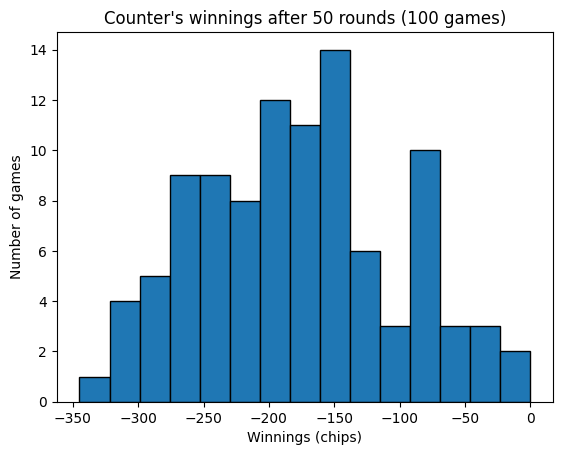

Average winnings per game: -178.8
Average winnings per round: -3.58
Standard deviation of winnings per game: 76.53
Probability of a net win: 0.0
Probability of a net loss: 0.99
Probability of breaking even: 0.01


In [22]:
import statistics
import matplotlib.pyplot as plt

num_games = 100
num_rounds = 50
starting_chips = 1000

# play 100 games of 50 rounds and save the counter's chips at the end of each
final_chips = []
for g in range(num_games):
    counter, others = run_test(num_rounds, starting_chips)
    final_chips.append(counter.chips)

# winnings = how many chips the counter gained or lost during the game
winnings = [chips - starting_chips for chips in final_chips]

# histogram
plt.hist(winnings, bins=15, edgecolor="black")
plt.title("Counter's winnings after 50 rounds (100 games)")
plt.xlabel("Winnings (chips)")
plt.ylabel("Number of games")
plt.show()

# statistics
avg_game = statistics.mean(winnings)
avg_round = avg_game / num_rounds
std = statistics.stdev(winnings)

wins = sum(1 for w in winnings if w > 0)
losses = sum(1 for w in winnings if w < 0)
even = sum(1 for w in winnings if w == 0)

print("Average winnings per game:", round(avg_game, 2))
print("Average winnings per round:", round(avg_round, 2))
print("Standard deviation of winnings per game:", round(std, 2))
print("Probability of a net win:", wins / num_games)
print("Probability of a net loss:", losses / num_games)
print("Probability of breaking even:", even / num_games)

threshold | avg/game | avg/round |  std | P(win) | P(loss) | copycat avg/game
  -100    |    -46.5 |     -0.93 | 77.2 |   0.26 |    0.73 |    -31.2
   -12    |    -54.4 |     -1.09 | 61.5 |   0.18 |    0.79 |    -28.0
    -8    |    -66.5 |     -1.33 | 64.1 |   0.15 |    0.85 |    -30.7
    -4    |   -113.7 |     -2.27 | 77.3 |   0.07 |    0.93 |    -25.5
     0    |   -166.0 |     -3.32 | 79.3 |   0.01 |    0.99 |    -25.8
     4    |   -258.6 |     -5.17 | 74.1 |   0.00 |    1.00 |    -28.6
     8    |   -299.0 |     -5.98 | 57.3 |   0.00 |    1.00 |    -27.1
    12    |   -317.3 |     -6.35 | 57.9 |   0.00 |    1.00 |    -29.4
   100    |   -326.8 |     -6.54 | 52.0 |   0.00 |    1.00 |    -23.1


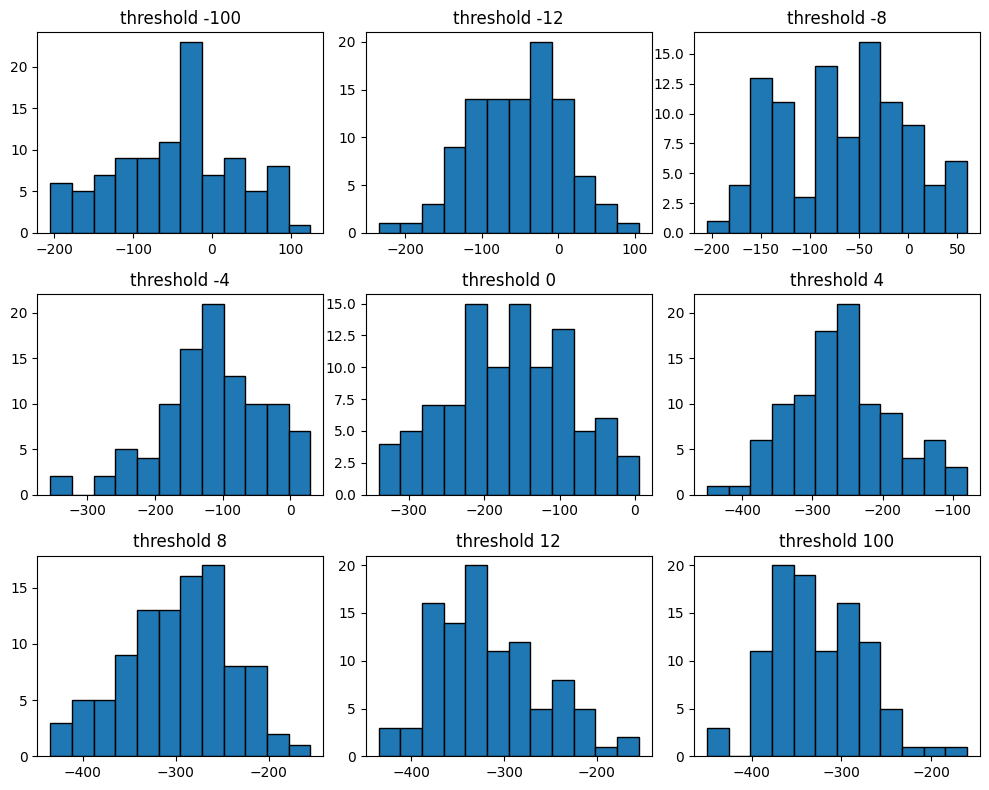

In [23]:
import statistics
import matplotlib.pyplot as plt

def run_test(num_rounds=50, starting_chips=1000, threshold=0):
    counter = Player("Counter", starting_chips, CardCountingStrategy(threshold=threshold))
    others = [Player("Copycat1", starting_chips, BasicStrategy()),
              Player("Copycat2", starting_chips, BasicStrategy()),
              Player("Copycat3", starting_chips, BasicStrategy())]

    game = Game([counter] + others, verbose=False)

    for i in range(num_rounds):
        if counter.chips <= 0:
            break
        game.play_round()

    return counter, others


def test_threshold(threshold, num_games=100, num_rounds=50, starting_chips=1000):
    winnings = []             # counter's winnings, one per game
    copycat_winnings = []     # copycats' winnings, for comparison
    for g in range(num_games):
        counter, others = run_test(num_rounds, starting_chips, threshold)
        winnings.append(counter.chips - starting_chips)
        for p in others:
            copycat_winnings.append(p.chips - starting_chips)
    return winnings, copycat_winnings


thresholds = [-100, -12, -8, -4, 0, 4, 8, 12, 100]
num_games = 100          # try 1000 for steadier numbers

all_winnings = {}
print("threshold | avg/game | avg/round |  std | P(win) | P(loss) | copycat avg/game")
for t in thresholds:
    winnings, copy = test_threshold(t, num_games)
    all_winnings[t] = winnings

    avg = statistics.mean(winnings)
    std = statistics.stdev(winnings)
    p_win = sum(1 for w in winnings if w > 0) / num_games
    p_loss = sum(1 for w in winnings if w < 0) / num_games
    print("%6d    | %8.1f | %9.2f | %4.1f | %6.2f | %7.2f | %8.1f" %
          (t, avg, avg / 50, std, p_win, p_loss, statistics.mean(copy)))

# one histogram per threshold
fig, axes = plt.subplots(3, 3, figsize=(10, 8))
for ax, t in zip(axes.flatten(), thresholds):
    ax.hist(all_winnings[t], bins=12, edgecolor="black")
    ax.set_title("threshold " + str(t))
plt.tight_layout()
plt.show()

In [24]:
class BasicTableStrategy(Strategy):
    def choose_action(self, hand, dealer_card):
        total = hand.get_total()
        up = dealer_card.get_value()     # dealer's visible card (ace = 11)

        if hand.is_soft():               # hand has an ace counting as 11
            if total >= 19:
                return "stand"
            if total == 18:
                if up >= 9:              # dealer has 9, 10 or ace
                    return "hit"
                return "stand"
            return "hit"

        # hard totals (no ace counting as 11)
        if total >= 17:
            return "stand"
        if total >= 13:
            if up <= 6:                  # dealer is weak, let them bust
                return "stand"
            return "hit"
        if total == 12:
            if up >= 4 and up <= 6:
                return "stand"
            return "hit"
        return "hit"                     # 11 or less can't bust

In [25]:
class CountingTableStrategy(BasicTableStrategy):
    def __init__(self, min_bet=10, max_bet=100, num_decks=6):
        BasicTableStrategy.__init__(self, min_bet, max_bet)
        self.num_decks = num_decks
        self.running_count = 0
        self.cards_seen = 0
        self.total_bet = 0               # so we can see how much money was wagered

    def see_card(self, card):
        if card.rank in ["2", "3", "4", "5", "6"]:
            self.running_count = self.running_count + 1
        elif card.rank in ["10", "J", "Q", "K", "A"]:
            self.running_count = self.running_count - 1
        self.cards_seen = self.cards_seen + 1

    def true_count(self):
        decks_left = self.num_decks - self.cards_seen / 52
        if decks_left < 0.5:
            decks_left = 0.5
        return self.running_count / decks_left

    def choose_bet(self, chips):
        tc = self.true_count()
        if tc < 2:
            bet = self.min_bet                          # count isn't favorable
        else:
            bet = min(self.min_bet * int(tc), self.max_bet)   # bigger bet when it is
        bet = min(bet, chips)
        self.total_bet = self.total_bet + bet
        return bet

    def reset_count(self):
        self.running_count = 0
        self.cards_seen = 0

In [26]:
def run_comparison(num_rounds=50, starting_chips=1000):
    copycat = Player("Copycat", starting_chips, BasicStrategy())
    table = Player("Table", starting_chips, BasicTableStrategy())
    counting = Player("Counting", starting_chips, CountingTableStrategy())
    game = Game([copycat, table, counting], verbose=False)
    for i in range(num_rounds):
        game.play_round()
    return copycat, table, counting


num_games = 2000
results = {"Copycat": [], "Table": [], "Counting": []}

for g in range(num_games):
    c, t, k = run_comparison()
    results["Copycat"].append(c.chips - 1000)
    results["Table"].append(t.chips - 1000)
    results["Counting"].append(k.chips - 1000)

for name in results:
    w = results[name]
    avg = statistics.mean(w)
    std = statistics.stdev(w)
    se = std / (num_games ** 0.5)       # standard error of the average
    print(name, "avg per game:", round(avg, 1), "| per round:", round(avg / 50, 2),
          "| std:", round(std, 1), "| standard error:", round(se, 1))

# same-cards difference: is Table really better than Copycat?
diff = [a - b for a, b in zip(results["Table"], results["Copycat"])]
print("Table minus Copycat per game:", round(statistics.mean(diff), 1),
      "+/-", round(statistics.stdev(diff) / (num_games ** 0.5), 1))

Copycat avg per game: -27.5 | per round: -0.55 | std: 68.8 | standard error: 1.5
Table avg per game: -13.2 | per round: -0.26 | std: 68.2 | standard error: 1.5
Counting avg per game: -10.2 | per round: -0.2 | std: 103.4 | standard error: 2.3
Table minus Copycat per game: 14.3 +/- 1.9
